In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
df = pd.read_csv('heart.csv')

In [5]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [7]:
df[df.duplicated()]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


In [8]:
df.drop_duplicates(keep = 'first', inplace = True)

**gender categorization**

number of people having sex ans 1 are 206


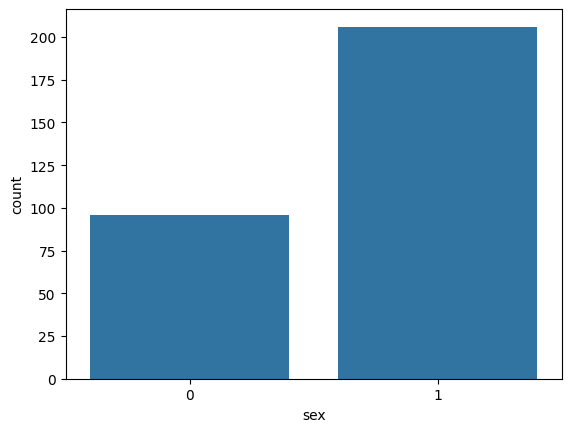

In [9]:
x= (df.sex.value_counts())
print(f'number of people having sex ans 1 are {x[1]}') and print(f'number of people having sex ans 0 are {x[0]}')
p = sns.countplot(data = df , x="sex")

In [10]:
x= (df.cp.value_counts())
print(x)
plt.show()

cp
0    143
2     86
1     50
3     23
Name: count, dtype: int64


**age distribution**

<Figure size 1000x1000 with 0 Axes>

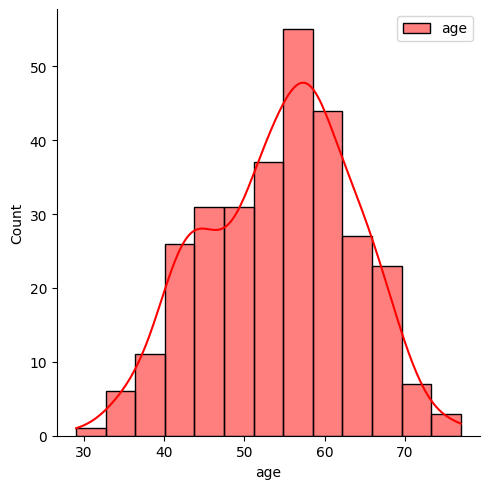

In [11]:
plt.figure(figsize = (10,10))
sns.displot(df.age , color ='red' , label = "age" , kde =True )
plt.legend()

<Figure size 1000x1000 with 0 Axes>

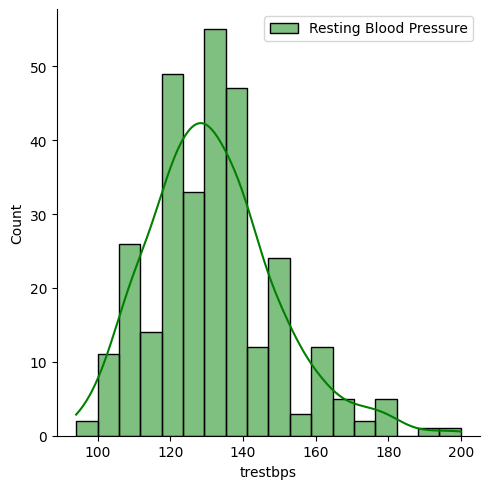

In [12]:
plt.figure(figsize = (10,10))
sns.displot(df.trestbps , color ='green' , label = "Resting Blood Pressure" , kde =True )
plt.legend()

/tmp/ipykernel_740/3610549572.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


<Figure size 1000x1000 with 0 Axes>

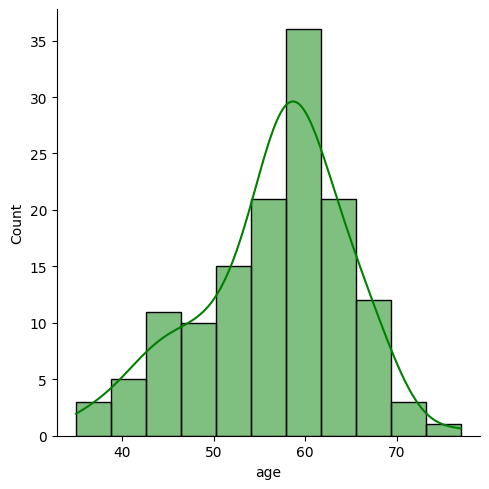

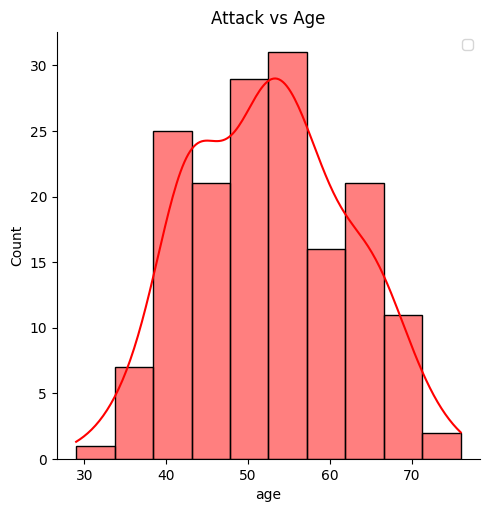

In [13]:
plt.figure(figsize = (10,10))
sns.displot(df[df['target']== 0]['age'] , color ='green' , kde =True ) #not get heartattack
sns.displot(df[df['target']== 1]['age'] , color ='red' , kde =True )  #will get heartaattack
plt.title("Attack vs Age")
plt.legend()

In [14]:
y = df.iloc[: , -1].values
x = df.iloc[: , :-1].values

In [15]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size = 0.2 , random_state = 42)

In [20]:
# Import StandardScaler to standardize features by removing mean and scaling to unit variance
from sklearn.preprocessing import StandardScaler

# Initialize the scaler instance
sc = StandardScaler()

# Calculate mean and standard deviation on x_train, then scale x_train
x_train = sc.fit_transform(x_train)

# Scale x_test using the mean and standard deviation learned from x_train (prevents data leakage)
x_test = sc.transform(x_test)

In [21]:
# Import the Gaussian Naive Bayes classifier from scikit-learn
from sklearn.naive_bayes import GaussianNB

# Initialize the Gaussian Naive Bayes classifier instance
classifier = GaussianNB()

# Train (fit) the classifier model using the training features (x_train) and target labels (y_train)
classifier.fit(x_train, y_train)

GaussianNB()

In [22]:
# Predict the class labels for the test dataset (x_test) using the trained classifier
y_pred = classifier.predict(x_test)

In [23]:
# Import confusion_matrix and accuracy_score to evaluate model performance
from sklearn.metrics import confusion_matrix, accuracy_score

# Compute the confusion matrix comparing actual test labels (y_test) with predicted labels (y_pred)
cm = confusion_matrix(y_test, y_pred)

# Print the resulting 2x2 confusion matrix showing true positives, true negatives, false positives, and false negatives
print(cm)

# Calculate and return the classification accuracy score on the test set
accuracy_score(y_test, y_pred)

[[27  2]
 [ 5 27]]


0.8852459016393442